In [1]:
#Importing the libraries

import pandas as pd    #For Data Collection and for data cleaning
from sklearn.model_selection import train_test_split #80% for training and 20% for testing
from sklearn.ensemble import RandomForestRegressor   #Model used for fitting training variables and predictions are made on independent testing variable
from sklearn.metrics import r2_score  #Model Evaluation
import plotly.express as px   #Advanced Data Visualisation
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv(r"C:\Users\Damya\Downloads\Real estate.csv")

In [3]:
df

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


In [4]:
#Dropping the unwanted column(s)

df = df.drop(columns = ['No'])

In [5]:
df

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...
409,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


In [6]:
df.head(3)

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3


In [7]:
df.tail()

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
409,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5
413,2013.500,6.5,90.45606,9,24.97433,121.54310,63.9


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   X1 transaction date                     414 non-null    float64
 1   X2 house age                            414 non-null    float64
 2   X3 distance to the nearest MRT station  414 non-null    float64
 3   X4 number of convenience stores         414 non-null    int64  
 4   X5 latitude                             414 non-null    float64
 5   X6 longitude                            414 non-null    float64
 6   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


In [9]:
df.describe()

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [10]:
corr = df.corr()

In [11]:
corr

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
X1 transaction date,1.000000,0.017549,0.060880,0.009635,0.035058,-0.041082,0.087491
X2 house age,0.017549,1.000000,0.025622,0.049593,0.054420,-0.048520,-0.210567
X3 distance to the nearest MRT station,0.060880,0.025622,1.000000,-0.602519,-0.591067,-0.806317,-0.673613
X4 number of convenience stores,0.009635,0.049593,-0.602519,1.000000,0.444143,0.449099,0.571005
X5 latitude,0.035058,0.054420,-0.591067,0.444143,1.000000,0.412924,0.546307
X6 longitude,-0.041082,-0.048520,-0.806317,0.449099,0.412924,1.000000,0.523287
Y house price of unit area,0.087491,-0.210567,-0.673613,0.571005,0.546307,0.523287,1.000000


In [12]:
import seaborn as sns

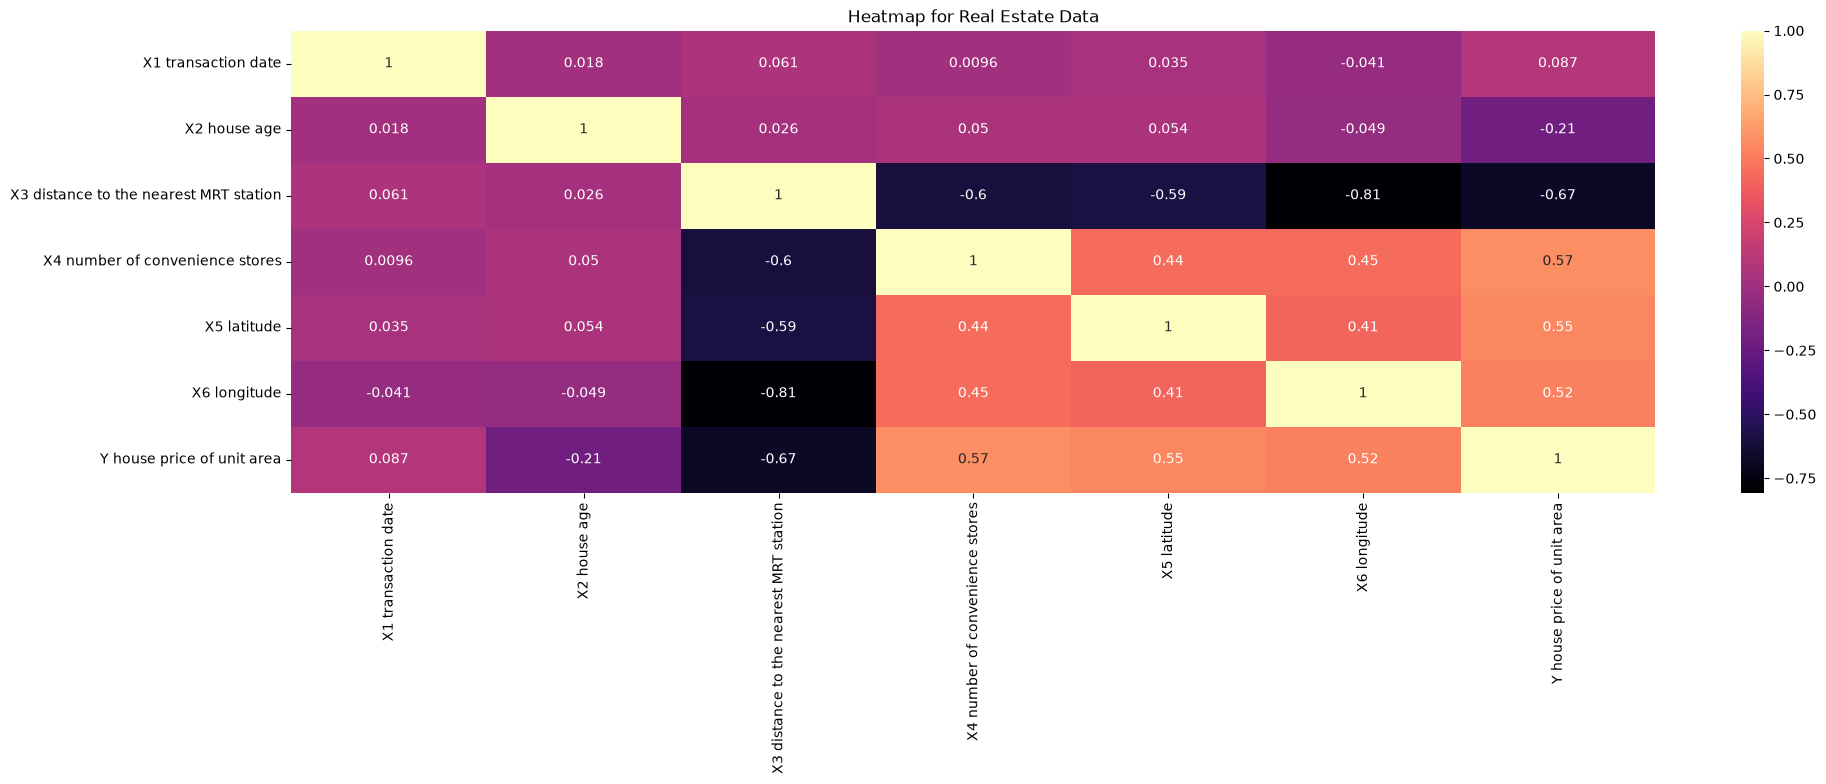

In [13]:
plt.figure(figsize = (22,6))
sns.heatmap(corr, annot = True, cmap = 'magma')
plt.title('Heatmap for Real Estate Data')
plt.show()

In [14]:
df.isnull().sum()

X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

Data Division into X and y

In [15]:
df.columns

Index(['X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='str')

In [16]:
X = df.drop(columns = ['Y house price of unit area'])
y = df['Y house price of unit area']

In [17]:
X

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,2012.917,32.0,84.87882,10,24.98298,121.54024
1,2012.917,19.5,306.59470,9,24.98034,121.53951
2,2013.583,13.3,561.98450,5,24.98746,121.54391
3,2013.500,13.3,561.98450,5,24.98746,121.54391
4,2012.833,5.0,390.56840,5,24.97937,121.54245
...,...,...,...,...,...,...
409,2013.000,13.7,4082.01500,0,24.94155,121.50381
410,2012.667,5.6,90.45606,9,24.97433,121.54310
411,2013.250,18.8,390.96960,7,24.97923,121.53986
412,2013.000,8.1,104.81010,5,24.96674,121.54067


In [18]:
y

0      37.9
1      42.2
2      47.3
3      54.8
4      43.1
       ... 
409    15.4
410    50.0
411    40.6
412    52.5
413    63.9
Name: Y house price of unit area, Length: 414, dtype: float64

Splitting the data into training and testing

In [19]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [20]:
X_train

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
192,2013.167,43.8,57.58945,7,24.96750,121.54069
234,2013.250,8.0,2216.61200,4,24.96007,121.51361
5,2012.667,7.1,2175.03000,3,24.96305,121.51254
45,2013.083,36.6,488.81930,8,24.97015,121.54494
245,2013.417,7.5,639.61980,5,24.97258,121.54814
...,...,...,...,...,...,...
71,2013.083,35.5,640.73910,3,24.97563,121.53715
106,2013.083,17.2,189.51810,8,24.97707,121.54308
270,2013.333,10.8,252.58220,1,24.97460,121.53046
348,2012.833,4.6,259.66070,6,24.97585,121.54516


In [21]:
X_test

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
358,2013.167,1.1,193.5845,6,24.96571,121.54089
350,2013.000,13.2,492.2313,5,24.96515,121.53737
373,2013.083,0.0,274.0144,1,24.97480,121.53059
399,2012.917,12.7,170.1289,1,24.97371,121.52984
369,2012.667,20.2,2185.1280,3,24.96322,121.51237
...,...,...,...,...,...,...
31,2012.750,29.6,769.4034,7,24.98281,121.53408
283,2013.417,33.5,1978.6710,2,24.98674,121.51844
157,2013.250,16.1,815.9314,4,24.97886,121.53464
203,2012.667,15.6,289.3248,5,24.98203,121.54348


In [22]:
y_train

192     42.7
234     23.9
5       32.1
45      38.3
245     40.8
       ...  
71      40.8
106     47.1
270    117.5
348     53.7
102     54.4
Name: Y house price of unit area, Length: 331, dtype: float64

In [23]:
y_test

358    45.1
350    42.3
373    52.2
399    37.3
369    22.8
       ... 
31     25.0
283    23.5
157    35.6
203    46.1
208    26.2
Name: Y house price of unit area, Length: 83, dtype: float64

Model Calling for Fitting Training Variables and Making predictions on independent testing variable

In [33]:
model = RandomForestRegressor(n_estimators = 100)

In [34]:
model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [35]:
p = model.predict(X_test)

In [36]:
p

array([48.635     , 38.925     , 53.93959167, 33.668     , 26.54      ,
       46.59063333, 47.714     , 50.958     , 14.428     , 60.2665    ,
       26.139     , 32.235     , 33.1922    , 14.533     , 36.014     ,
       24.223     , 39.5375    , 53.0772    , 25.097     , 38.263     ,
       15.856     , 23.365     , 48.0055    , 47.62777857, 13.05633333,
       34.51475   , 15.85133333, 55.329675  , 52.287     , 36.95733333,
       20.666     , 25.984     , 35.556     , 25.45      , 47.09666667,
       37.61266667, 54.4575    , 15.99286667, 46.6508    , 53.463     ,
       47.423     , 41.0725    , 47.884     , 38.395     , 39.985     ,
       49.795     , 34.82566667, 23.913     , 48.5528    , 47.266     ,
       48.137     , 55.13      , 40.69966667, 38.19      , 40.399     ,
       16.50286667, 37.225     , 26.9605    , 25.499     , 52.562     ,
       27.135     , 24.811     , 16.50286667, 13.941     , 20.296     ,
       23.317     , 25.719     , 40.15666667, 35.392     , 26.87

In [37]:
y_test

358    45.1
350    42.3
373    52.2
399    37.3
369    22.8
       ... 
31     25.0
283    23.5
157    35.6
203    46.1
208    26.2
Name: Y house price of unit area, Length: 83, dtype: float64

In [38]:
r2 = r2_score(y_test,p)

In [39]:
r2

0.8078208164609569

In [40]:
m1 = model.score(X_train,y_train)
m2 = model.score(X_test,y_test)

In [41]:
print('Training Score : ',m1*100,'%')
print('Testing Score : ',m2*100,'%')

Training Score :  94.95299286114549 %
Testing Score :  80.78208164609569 %


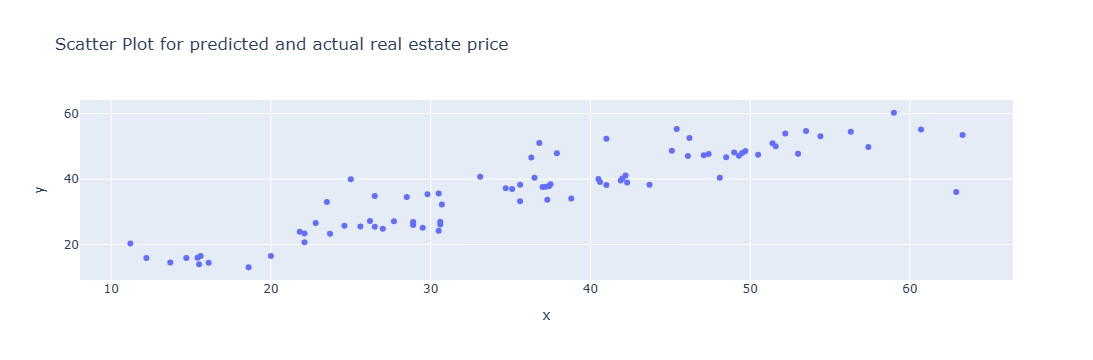

In [42]:
px.scatter(x = y_test, y  = p, title = 'Scatter Plot for predicted and actual real estate price').show()

In [43]:
fi = model.feature_importances_

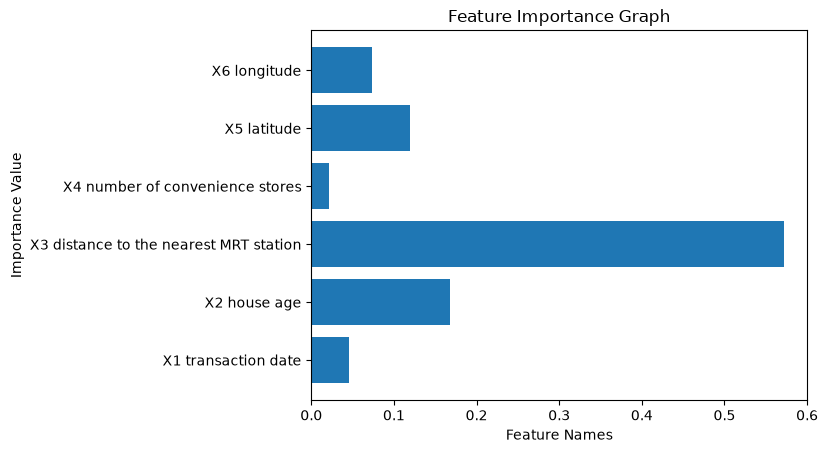

In [44]:
plt.barh(X.columns, fi)
plt.xlabel('Feature Names')
plt.ylabel('Importance Value')
plt.title('Feature Importance Graph')
plt.show()